# Interpretación de los grupos

## Entorno

Importé las librerías y fijé la semilla 42, que usan la partición y todos los modelos. Sin semilla,
K-Means y GMM arrancan desde centroides o componentes distintos en cada corrida, así que los grupos, su
numeración y las métricas cambiarían, y nadie podría verificar las cifras del informe. También imprimí
las versiones de Python, NumPy, pandas, scikit-learn y Matplotlib, porque los valores por defecto de los
estimadores cambian de una versión a otra y con ellos los resultados.

Definí tres funciones auxiliares. La función redondear aplica redondeo mitad hacia arriba una sola vez
sobre el valor completo. La usé en todas las cifras que se guardan porque round de Python trabaja sobre
la representación binaria y, por ejemplo, redondea 0,2175 a 0,217, mientras que el informe diría 0,218.
Así cada número se ve igual en el notebook y en el informe. La función guardar escribe la figura en
splits antes de mostrarla, porque plt.show libera la figura y el archivo saldría en blanco. La función
guardar_resultados agrega las cifras de cada notebook a resultados.json, de donde las toma el informe sin
copiarlas a mano.

In [1]:
import os, time, json, platform, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import joblib
from decimal import Decimal, ROUND_HALF_UP

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 40)
plt.rcParams['figure.dpi'] = 100
SEMILLA = 42
np.random.seed(SEMILLA)

EN_DRIVE = False
try:
    from google.colab import drive
    drive.mount('/content/drive')
    if not os.path.isdir('/content/drive/MyDrive'):
        raise RuntimeError('Drive no quedó montado. Vuelve a ejecutar esta celda y autoriza el acceso '
                           'en la ventana emergente.')
    RUTA = '/content/drive/MyDrive/credit_card'
    EN_DRIVE = True
except ImportError:
    RUTA = os.path.abspath('..' if os.path.basename(os.getcwd()) == 'notebooks' else '.')

CARPETA_SPLITS = os.path.join(RUTA, 'splits')
os.makedirs(CARPETA_SPLITS, exist_ok=True)
ARCHIVO_RESULTADOS = os.path.join(RUTA, 'resultados.json')
resultados = {}
if os.path.exists(ARCHIVO_RESULTADOS):
    with open(ARCHIVO_RESULTADOS, encoding='utf-8') as f:
        resultados = json.load(f)

def redondear(valor, decimales=3):
    r = Decimal(repr(float(valor))).quantize(Decimal(1).scaleb(-decimales), rounding=ROUND_HALF_UP)
    return int(r) if decimales == 0 else float(r)

def redondear_serie(serie, decimales=3):
    return serie.map(lambda v: redondear(v, decimales))

def guardar(nombre):
    plt.tight_layout()
    plt.savefig(os.path.join(CARPETA_SPLITS, nombre + '.png'), dpi=150, bbox_inches='tight', facecolor='white')
    print('Gráfico guardado:', nombre + '.png')
    plt.show()

def guardar_resultados():
    with open(ARCHIVO_RESULTADOS, 'w', encoding='utf-8') as f:
        json.dump(resultados, f, ensure_ascii=False, indent=1,
                  default=lambda o: o.item() if hasattr(o, 'item') else str(o))
    print('Cifras guardadas en resultados.json')

resultados['versiones'] = {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
                           'scikit-learn': sklearn.__version__, 'matplotlib': matplotlib.__version__}
print('Guardando en Google Drive' if EN_DRIVE else 'Google Drive no disponible, guardando localmente')
print('Versiones:', resultados['versiones'])

Google Drive no disponible, guardando localmente
Versiones: {'python': '3.12.10', 'numpy': '2.2.6', 'pandas': '3.0.3', 'scikit-learn': '1.8.0', 'matplotlib': '3.10.9'}


## Carga de los datos preparados

Cargué de datos_preparados.joblib lo que dejó el notebook 03, las particiones de entrenamiento y prueba
en unidades originales y transformadas, las listas de columnas y la marca de atípicos. Usar ese archivo
en lugar de repetir el preprocesamiento garantiza que el transformador sea exactamente el que se ajustó
con entrenamiento. También cargué las etiquetas de la etapa 1 y de la etapa 2.

In [2]:
prep = joblib.load(os.path.join(RUTA, 'datos_preparados.joblib'))
X_train, X_test, X_tr, X_te = prep['X_train'], prep['X_test'], prep['X_tr'], prep['X_te']
MONTOS, RESTO, COLUMNAS, frecuencias, fuera = prep['MONTOS'], prep['RESTO'], prep['COLUMNAS'], prep['frecuencias'], prep['fuera']
print('Entrenamiento:', X_tr.shape, '| Prueba:', X_te.shape)

e1 = joblib.load(os.path.join(RUTA, 'etapa1.joblib'))
K_KM, COV, REG, K_GMM = e1['K_KM'], e1['COV'], e1['REG'], e1['K_GMM']
et_km_tr, et_km_te, et_gm_tr, et_gm_te = e1['et_km_tr'], e1['et_km_te'], e1['et_gm_tr'], e1['et_gm_te']
print('Etapa 1, K-Means con K =', K_KM, '| GMM', COV, 'reg_covar', REG, 'K =', K_GMM)

e2 = joblib.load(os.path.join(RUTA, 'etapa2.joblib'))
K_KM_PCA, et_kmp_tr = e2['K_KM_PCA'], e2['et_kmp_tr']
print('Etapa 2, K-Means en PCA con K =', K_KM_PCA)

Entrenamiento: (7160, 17) | Prueba: (1790, 17)
Etapa 1, K-Means con K = 6 | GMM diag reg_covar 1.0 K = 6
Etapa 2, K-Means en PCA con K = 7


## Perfiles en unidades originales

Describí cada grupo con la mediana de las variables sin transformar, porque al banco le dice más un saldo
de 1 671 que un valor estandarizado. Usé la mediana porque resiste mejor que la media a los clientes
extremos. El mapa de calor, en cambio, usa la media estandarizada de cada grupo y muestra en qué se aleja
cada uno del cliente promedio. Empiezo por los grupos de K-Means en el espacio original.

Gráfico guardado: 06_perfil_kmeans.png


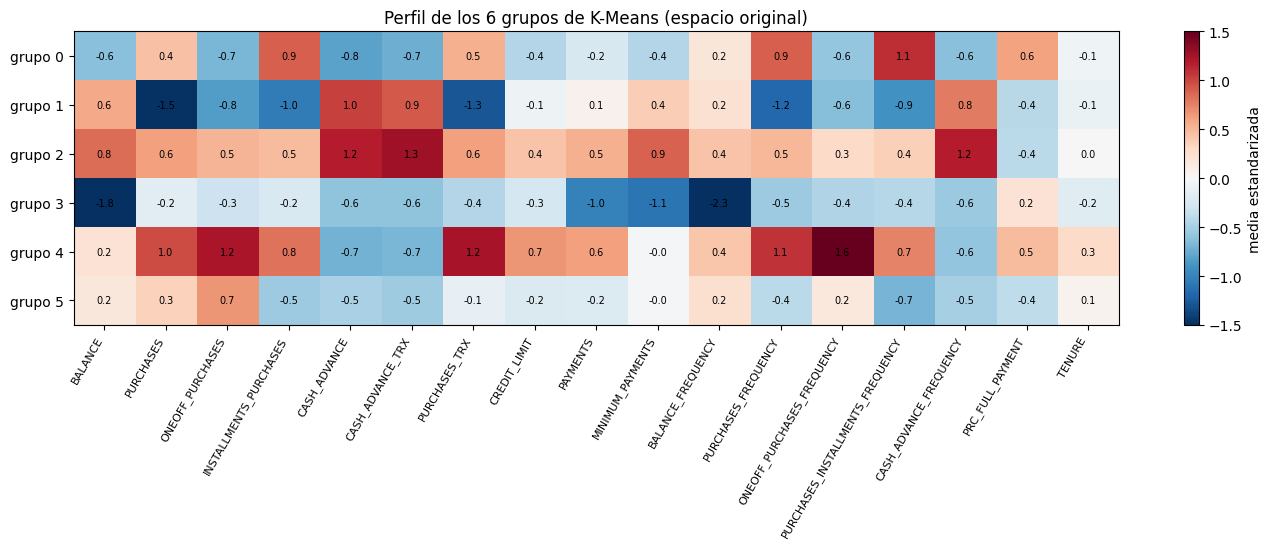

,clientes,por ciento,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,CASH_ADVANCE_FREQUENCY,CREDIT_LIMIT,PAYMENTS,PRC_FULL_PAYMENT,TENURE
grupo,,,,,,,,,,,,,
0,1353,18.9,100,478,0,443,0,0.92,0.00,2000,542,0.18,12
1,1762,24.6,1593,0,0,0,1377,0.00,0.25,3000,818,0.00,12
2,975,13.6,2755,793,360,300,2033,0.75,0.33,5000,1771,0.00,12
3,802,11.2,13,137,0,32,0,0.17,0.00,2700,270,0.00,12
4,1166,16.3,792,2340,1352,711,0,1.00,0.00,6500,2024,0.08,12
5,1102,15.4,899,418,333,0,0,0.27,0.00,2500,596,0.00,12


In [3]:
CLAVE = ['BALANCE', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE',
         'PURCHASES_FREQUENCY', 'CASH_ADVANCE_FREQUENCY', 'CREDIT_LIMIT', 'PAYMENTS', 'PRC_FULL_PAYMENT', 'TENURE']

def perfil(etiquetas):
    t = X_train.assign(grupo=etiquetas)
    p = t.groupby('grupo')[CLAVE].median()
    p = p.apply(lambda c: redondear_serie(c, 2 if 'FREQUENCY' in c.name or c.name == 'PRC_FULL_PAYMENT' else 0))
    p.insert(0, 'clientes', t['grupo'].value_counts().sort_index())
    p.insert(1, 'por ciento', redondear_serie(p['clientes'] / len(t) * 100, 1))
    return p

def mapa(etiquetas, nombre, titulo):
    z = pd.DataFrame(X_tr, columns=COLUMNAS).groupby(etiquetas).mean()
    fig, ax = plt.subplots(figsize=(14, 0.6 * len(z) + 2))
    im = ax.imshow(z, cmap='RdBu_r', vmin=-1.5, vmax=1.5, aspect='auto')
    ax.set_xticks(range(len(COLUMNAS)))
    ax.set_xticklabels(COLUMNAS, rotation=60, ha='right', fontsize=8)
    ax.set_yticks(range(len(z)))
    ax.set_yticklabels([f'grupo {i}' for i in z.index])
    for i in range(len(z)):
        for j in range(len(COLUMNAS)):
            ax.text(j, i, f'{z.iloc[i, j]:.1f}', ha='center', va='center', fontsize=7)
    fig.colorbar(im, label='media estandarizada')
    ax.set_title(titulo)
    guardar(nombre)

perfil_km, perfil_gm = perfil(et_km_tr), perfil(et_gm_tr)
resultados['perfil_km'] = perfil_km.to_dict(orient='index')
resultados['perfil_gmm'] = perfil_gm.to_dict(orient='index')
mapa(et_km_tr, '06_perfil_kmeans', f'Perfil de los {K_KM} grupos de K-Means (espacio original)')
perfil_km

Repetí la descripción con los seis grupos de GMM, para comparar los perfiles de los dos modelos en el
mismo espacio.

Gráfico guardado: 06_perfil_gmm.png


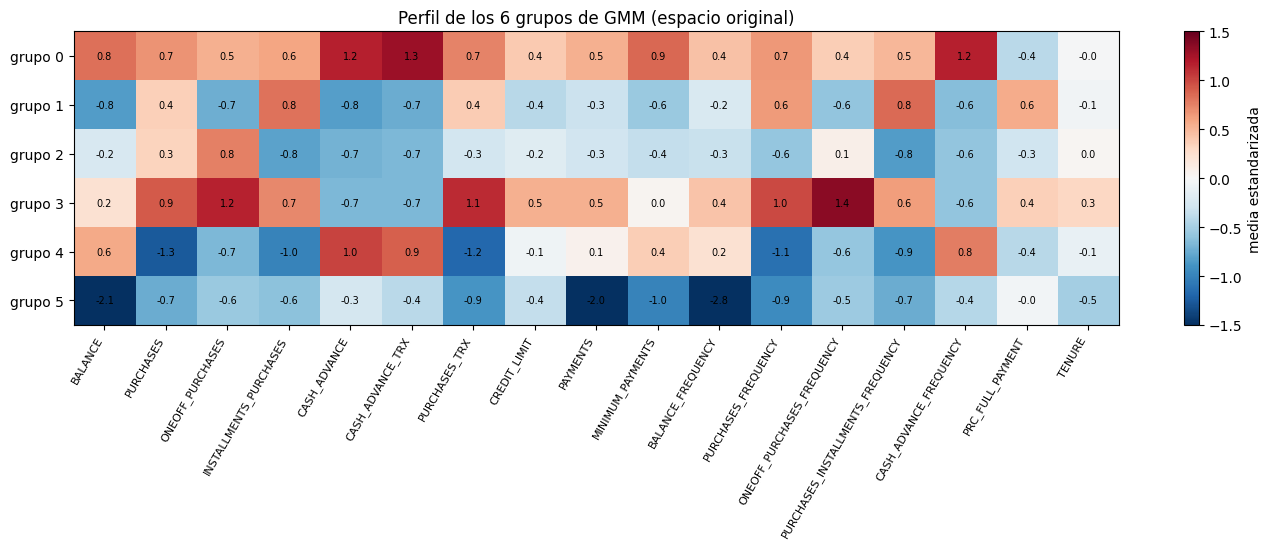

,clientes,por ciento,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,CASH_ADVANCE_FREQUENCY,CREDIT_LIMIT,PAYMENTS,PRC_FULL_PAYMENT,TENURE
grupo,,,,,,,,,,,,,
0,833,11.6,2646,912,400,379,1964,0.83,0.33,5000,1771,0.00,12
1,1684,23.5,71,390,0,355,0,0.83,0.00,2375,474,0.17,12
2,860,12.0,418,384,353,0,0,0.20,0.00,2900,564,0.00,12
3,1449,20.2,841,1977,1132,591,0,1.00,0.00,6000,1781,0.00,12
4,2059,28.8,1592,0,0,0,1335,0.00,0.25,3000,820,0.00,12
5,275,3.8,5,31,0,0,0,0.08,0.00,2500,72,0.00,12


In [4]:
mapa(et_gm_tr, '06_perfil_gmm', f'Perfil de los {K_GMM} grupos de GMM (espacio original)')
perfil_gm

En la etapa 1 los dos modelos dieron seis perfiles equivalentes, que se reconocen en los mapas por su
combinación de compras y efectivo. Hay compradores en cuotas, compradores premium que gastan mucho,
compradores ocasionales, usuarios de efectivo que casi no compran, intensivos endeudados que hacen las
dos cosas y clientes casi inactivos. La diferencia entre los modelos estuvo en los bordes, sobre todo en
el grupo de inactivos, que en GMM quedó mucho más chico.

Por último describí los siete grupos de K-Means en el espacio reducido, la configuración que recomiendo,
y les puse nombre y acción comercial a partir de sus medianas.

Gráfico guardado: 06_perfil_kmeans_pca.png


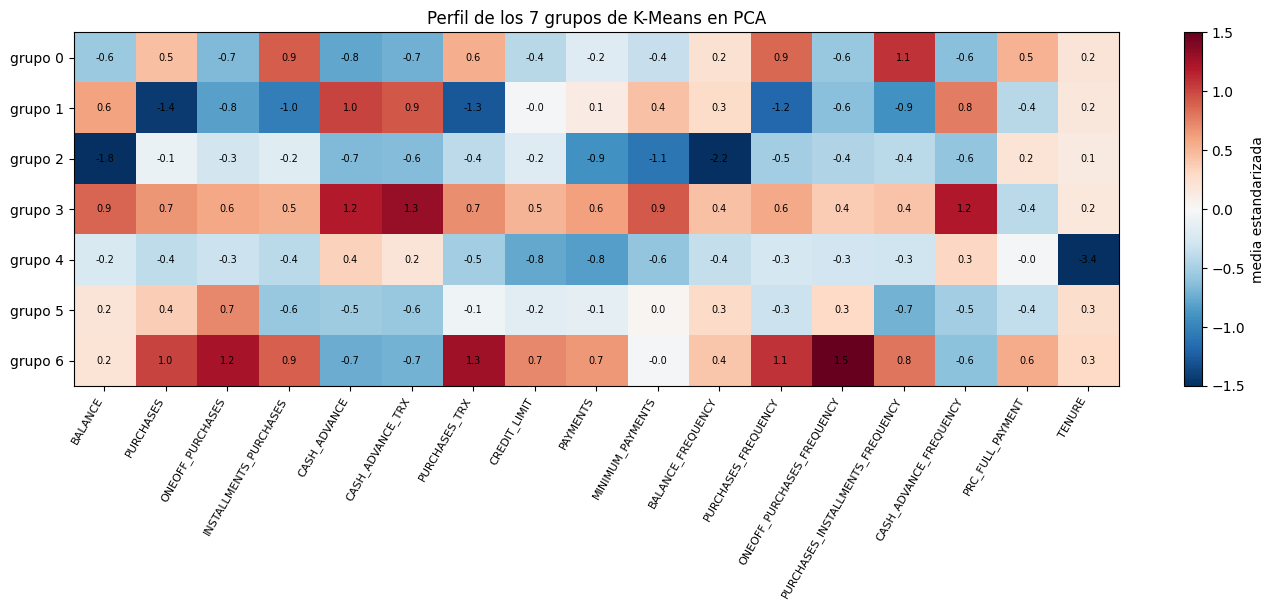

,clientes,por ciento,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,CASH_ADVANCE_FREQUENCY,CREDIT_LIMIT,PAYMENTS,PRC_FULL_PAYMENT,TENURE
grupo,,,,,,,,,,,,,
0,1329,18.6,125,500,0,450,0,0.92,0.00,2500,576,0.11,12
1,1678,23.4,1671,0,0,0,1351,0.00,0.25,3000,883,0.00,12
2,777,10.9,14,156,0,46,0,0.18,0.00,3000,295,0.00,12
3,882,12.3,2949,929,435,333,2116,0.75,0.33,6000,1965,0.00,12
4,402,5.6,486,154,0,0,509,0.25,0.14,1500,250,0.00,7
5,1019,14.2,939,450,381,0,0,0.33,0.00,3000,641,0.00,12
6,1073,15.0,751,2463,1409,763,0,1.00,0.00,6500,2137,0.08,12


In [5]:
perfil_kmp = perfil(et_kmp_tr)
resultados['perfil_km_pca'] = perfil_kmp.to_dict(orient='index')
mapa(et_kmp_tr, '06_perfil_kmeans_pca', f'Perfil de los {K_KM_PCA} grupos de K-Means en PCA')
perfil_kmp

Nombré los grupos de la configuración recomendada, K-Means sobre PCA, a partir de sus medianas en
unidades originales y del mapa de calor.

| Grupo | Clientes | Nombre | Rasgo principal | Acción del banco |
|---|---|---|---|---|
| 0 | 18,6 por ciento | Compradores en cuotas | Compran casi todos los meses (frecuencia 0,92), 450 en cuotas, saldo bajo y sin efectivo | Campañas de cuotas sin interés con comercios aliados |
| 1 | 23,4 por ciento | Usuarios de efectivo | No compran nada, retiran 1 351 en efectivo y deben 1 671 | Vigilar la mora y ofrecer un préstamo personal más barato que el avance |
| 2 | 10,9 por ciento | Inactivos | Saldo casi nulo y compras mínimas, con frecuencia de 0,18 | Campaña de reactivación o revisar el costo de mantener la tarjeta |
| 3 | 12,3 por ciento | Intensivos endeudados | Compran y además retiran efectivo, con el mayor saldo (2 949) y límite de 6 000 | Refinanciar la deuda y no aumentar el límite |
| 4 | 5,6 por ciento | Clientes nuevos | Antigüedad mediana de 7 meses, límite bajo (1 500) y algo de efectivo | Programa de acompañamiento en los primeros meses |
| 5 | 14,2 por ciento | Compradores ocasionales | Compras de un solo pago cada tanto (frecuencia 0,33) y sin efectivo | Promociones de temporada y ofrecer pasar compras grandes a cuotas |
| 6 | 15,0 por ciento | Compradores premium | Los que más compran (2 463), todos los meses, con el mayor límite (6 500) y sin efectivo | Tarjeta de categoría superior, programa de puntos y más límite |

Antes de entrenar esperaba cuatro perfiles, cliente que paga el total, cliente endeudado que retira
efectivo, comprador en cuotas y cliente inactivo. Los datos confirmaron tres (comprador en cuotas,
cliente que retira efectivo y cliente inactivo) y matizaron el cuarto. No apareció un grupo de clientes
que paguen el total de su deuda, porque la proporción de pagos totales tuvo una mediana entre 0 y 0,11 en
todos los grupos. El perfil más cercano fue el de compradores premium, que gastan mucho y no usan
efectivo pero tampoco pagan siempre el total. También surgieron tres segmentos que no había previsto. El
cliente endeudado se dividió entre quienes solo retiran efectivo y quienes además compran mucho, que son
los de mayor saldo. Los compradores ocasionales en un pago se separaron de los de cuotas. Y el
reentrenamiento en PCA aisló a los clientes nuevos, que el modelo original repartía entre los demás
grupos. Como el conjunto no tiene etiquetas de referencia, no calculé ARI ni NMI externos.

## Peso de cada grupo en el negocio

Calculé, para cada grupo de la configuración recomendada, qué parte del total de compras, de la deuda y
del efectivo retirado de la cartera de entrenamiento le corresponde, y la frecuencia media de compra y de
avances en efectivo. Un grupo puede tener pocos clientes y concentrar buena parte de la deuda, y ese
desbalance es el que dice dónde poner el esfuerzo comercial y dónde vigilar.

In [6]:
t = X_train.assign(grupo=et_kmp_tr)
totales = X_train[['PURCHASES', 'BALANCE', 'CASH_ADVANCE']].sum()
negocio = (t.groupby('grupo')[['PURCHASES', 'BALANCE', 'CASH_ADVANCE']].sum() / totales * 100)
negocio = negocio.apply(lambda c: redondear_serie(c, 1)).rename(columns={
    'PURCHASES': 'compras (por ciento)', 'BALANCE': 'deuda (por ciento)', 'CASH_ADVANCE': 'efectivo (por ciento)'})
negocio.insert(0, 'clientes (por ciento)', perfil_kmp['por ciento'])
frecuencias_medias = t.groupby('grupo')[['PURCHASES_FREQUENCY', 'CASH_ADVANCE_FREQUENCY']].mean()
negocio['frecuencia media de compra'] = redondear_serie(frecuencias_medias['PURCHASES_FREQUENCY'], 2)
negocio['frecuencia media de efectivo'] = redondear_serie(frecuencias_medias['CASH_ADVANCE_FREQUENCY'], 2)
resultados['negocio_km_pca'] = negocio.to_dict(orient='index')
negocio

,clientes (por ciento),compras (por ciento),deuda (por ciento),efectivo (por ciento),frecuencia media de compra,frecuencia media de efectivo
grupo,,,,,,
0,18.6,12.9,5.4,0.9,0.83,0.01
1,23.4,0.5,36.3,50.3,0.02,0.29
2,10.9,3.0,0.2,1.4,0.28,0.02
3,12.3,18.4,28.9,38.2,0.72,0.37
4,5.6,1.9,3.0,6.0,0.38,0.20
5,14.2,10.0,11.1,2.3,0.36,0.03
6,15.0,53.3,15.1,0.9,0.93,0.01


Los grupos pesan muy distinto en el negocio. Los compradores premium son el 15,0 por ciento de los
clientes y concentran el 53,3 por ciento de las compras, más de la mitad de todo lo comprado con tarjeta.
En el otro extremo, los usuarios de efectivo son el 23,4 por ciento de los clientes y tienen el 36,3 por
ciento de la deuda y el 50,3 por ciento del efectivo retirado. Los intensivos endeudados, con el 12,3 por
ciento de los clientes, suman el 28,9 por ciento de la deuda y el 38,2 por ciento del efectivo. Los
inactivos, con el 10,9 por ciento de los clientes, apenas tienen el 0,2 por ciento de la deuda y el 3,0
por ciento de las compras. Para el banco eso significa que retener a un grupo pequeño de compradores
sostiene la mayor parte de la facturación con tarjeta, y que la vigilancia de mora tiene que concentrarse
en los usuarios de efectivo y en los intensivos endeudados.

## Variables que definen la agrupación

Calculé el eta cuadrado de cada variable escalada, η² = SS_entre / SS_total. SS_total = Σ_i (x_i − x̄)²
es la variación total de la variable y SS_entre = Σ_k n_k (x̄_k − x̄)² la parte que explican las medias
de los grupos. Va de 0 a 1. Cerca de 1, la variable cambia mucho de un grupo a otro y casi nada dentro de
cada grupo, así que define la segmentación. Cerca de 0, no ayuda a separarlos. Lo calculé para las
particiones de K-Means en los dos espacios, siempre sobre las 17 variables escaladas, para que los
valores sean comparables.

Gráfico guardado: 06_eta_cuadrado.png


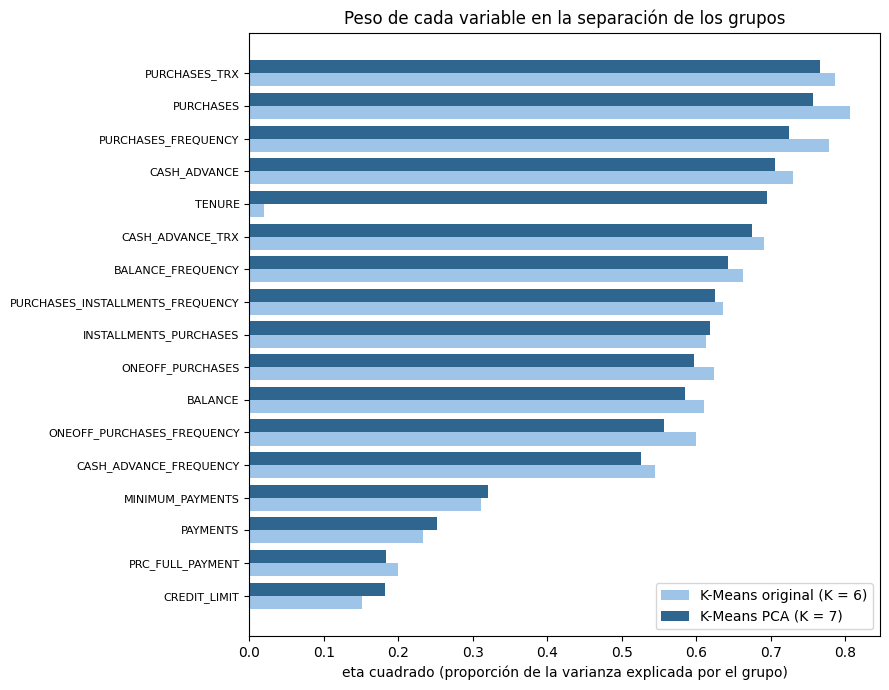

,K-Means original,K-Means PCA
PURCHASES_TRX,0.786,0.766
PURCHASES,0.806,0.757
PURCHASES_FREQUENCY,0.778,0.724
CASH_ADVANCE,0.729,0.706
TENURE,0.020,0.695
CASH_ADVANCE_TRX,0.690,0.675
BALANCE_FREQUENCY,0.662,0.642
PURCHASES_INSTALLMENTS_FREQUENCY,0.636,0.625
INSTALLMENTS_PURCHASES,0.613,0.618
ONEOFF_PURCHASES,0.623,0.597


In [7]:
def eta_cuadrado(etiquetas):
    Z = pd.DataFrame(X_tr, columns=COLUMNAS)
    total = ((Z - Z.mean()) ** 2).sum()
    medias = Z.groupby(etiquetas).transform('mean')
    entre = ((medias - Z.mean()) ** 2).sum()
    return redondear_serie(entre / total)

eta = pd.DataFrame({'K-Means original': eta_cuadrado(et_km_tr),
                    'K-Means PCA': eta_cuadrado(et_kmp_tr)}).sort_values('K-Means PCA')
resultados['eta_cuadrado'] = eta.to_dict()
fig, ax = plt.subplots(figsize=(9, 7))
y = np.arange(len(eta))
ax.barh(y - 0.2, eta['K-Means original'], height=0.4, color='#9ec5e8', label=f'K-Means original (K = {K_KM})')
ax.barh(y + 0.2, eta['K-Means PCA'], height=0.4, color='#2f6690', label=f'K-Means PCA (K = {K_KM_PCA})')
ax.set_yticks(y)
ax.set_yticklabels(eta.index, fontsize=8)
ax.set_xlabel('eta cuadrado (proporción de la varianza explicada por el grupo)')
ax.set_title('Peso de cada variable en la separación de los grupos')
ax.legend()
guardar('06_eta_cuadrado')
eta.sort_values('K-Means PCA', ascending=False)

Los grupos quedaron definidos sobre todo por cómo se usa la tarjeta para comprar y para sacar efectivo.
Las variables con más peso fueron el número de compras (eta cuadrado de 0,766 en la partición
recomendada), el monto comprado (0,757), la frecuencia de compra (0,724) y el monto retirado en efectivo
(0,706), seguidas por el número de avances, la frecuencia de movimiento del saldo y la forma de compra,
en cuotas o en un pago, todas por encima de 0,5. En cambio, cuánto paga el cliente, su pago mínimo, la
proporción de meses con pago total y el límite de crédito tuvieron pesos entre 0,182 y 0,320. Esas
variables casi no cambian de un grupo a otro, y por eso no apareció un segmento de clientes que paguen el
total de su deuda.

La antigüedad mostró la diferencia entre los dos espacios. En la partición original su peso fue de 0,020,
es decir que no intervenía, mientras que en la partición sobre PCA subió a 0,695. Es la variable que
define al séptimo grupo, el de clientes nuevos, que el modelo sobre PCA pudo aislar porque, al quitar la
redundancia entre las variables de compra, la antigüedad ganó peso relativo en las distancias.

En términos del negocio, el modelo responde dos preguntas sobre cada cliente, si usa la tarjeta para
comprar o para sacar efectivo y cuánto y cómo compra. A esas dos respuestas la versión sobre PCA le
agrega si el cliente es nuevo.

## Cierre del notebook

Guardé las cifras de este notebook en resultados.json.

In [8]:
guardar_resultados()

Cifras guardadas en resultados.json
